In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt


In [4]:
lu1901_1930 = xr.open_dataset("../data/LUclasses.zarr", group = '1901_1930')
lu1931_1960 = xr.open_dataset("../data/LUclasses.zarr", group = '1931_1960')

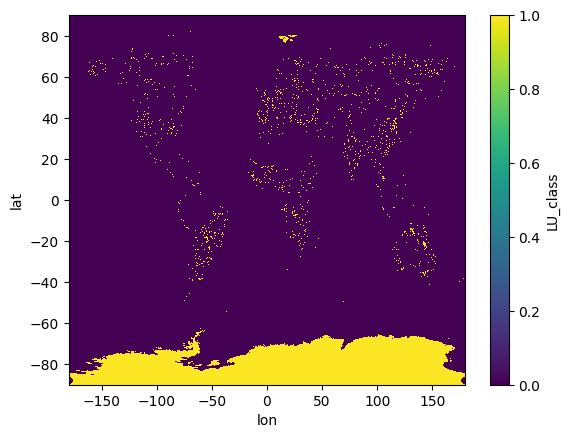

In [8]:
lu_diff = xr.where(lu1931_1960['LU_class'] != lu1901_1930['LU_class'], 1, 0)
lu_diff.plot()

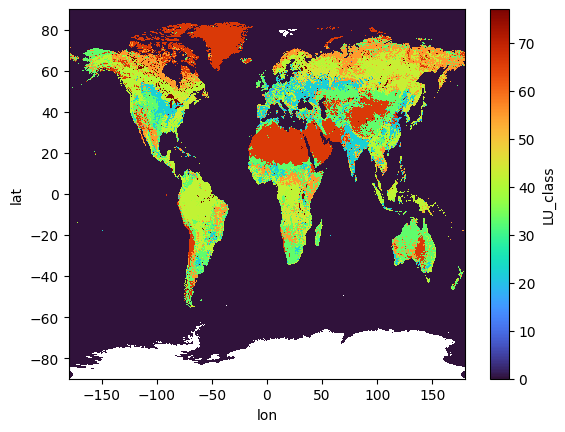

In [9]:
lu1901_1930['LU_class'].plot(cmap = 'turbo')

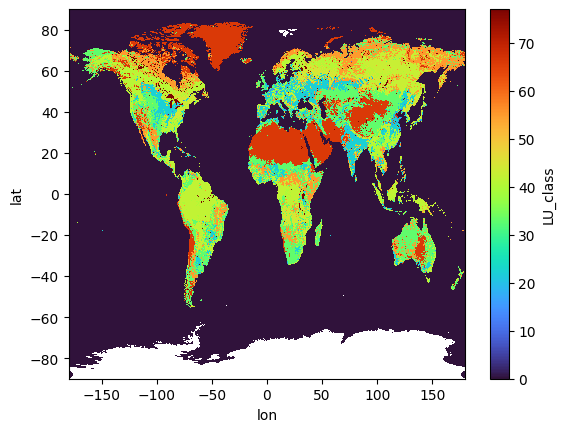

In [10]:
lu1931_1960['LU_class'].plot(cmap = 'turbo')

In [3]:
hildaStates = xr.open_dataset("../data-raw/HILDAp_v2/hildaplus_GLOB-2-0_states.nc")

In [5]:
LU126 = xr.open_dataset("../data-raw/FutureLU/SSP1_RCP26_country-f.tif")

In [6]:
LU126

<xarray.Dataset> Size: 365GB
Dimensions:      (band: 141, x: 36000, y: 18000)
Coordinates:
  * band         (band) int64 1kB 1 2 3 4 5 6 7 ... 135 136 137 138 139 140 141
  * x            (x) float64 288kB -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * y            (y) float64 144kB 90.0 89.99 89.98 ... -89.98 -89.99 -90.0
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) float32 365GB ...

In [4]:
hildaStates

<xarray.Dataset> Size: 314GB
Dimensions:      (time: 121, latitude: 18000, longitude: 36000)
Coordinates:
  * time         (time) float32 484B 1.9e+03 1.901e+03 ... 2.019e+03 2.02e+03
  * latitude     (latitude) float32 72kB 90.0 89.99 89.97 ... -89.99 -90.0
  * longitude    (longitude) float32 144kB -180.0 -180.0 -180.0 ... 180.0 180.0
Data variables:
    LULC_states  (time, latitude, longitude) float32 314GB ...
Attributes:
    description:      HILDA+ land use/cover reconstruction - LULC states
    version:          GLOB-2.1-crop
    info:             annual land cover/use maps 1900-2020
    temp_coverage:    1900-2020
    spat_coverage:    -180,-90: 180,90
    temp_resolution:  annual
    spat_resolution:  0.01 degree
    projection:       EPSG:4326 - WGS 84 – Geographic
    producer:         Winkler, Karina (KIT)

In [4]:
hildaLU_1900_1930 = hildaStates.sel(time=slice(1900, 1930))["LULC_states"]

In [5]:
# Source - https://stackoverflow.com/a/56334302
# Posted by jhamman
# Retrieved 2026-05-04, License - CC BY-SA 4.0

import scipy

def _mode(*args, **kwargs):
    vals = scipy.stats.mode(*args, **kwargs)
    # only return the mode (discard the count)
    return vals[0].squeeze()

def mode(obj, dim):
    # note: apply always moves core dimensions to the end
    # usually axis is simply -1 but scipy's mode function doesn't seem to like that
    # this means that this version will only work for DataArray's (not Datasets)
    assert isinstance(obj, xr.DataArray)
    axis = obj.ndim - 1
    return xr.apply_ufunc(
        _mode,
        obj,
        input_core_dims=[[dim]],
        output_core_dims=[[]],
        kwargs={'axis': axis}
    )

In [ ]:
# resample from 0.01 degree to 0.05 degree resolution
# coarsen by a factor of 5 on lat and lon, then take the mode
hildaLU_1900_1930_0p05 = hildaLU_1900_1930.coarsen(latitude=5, longitude=5, boundary='trim').construct({"latitude": ("latitude", "latitude_window"), "longitude": ("longitude", "longitude_window")})
hildaLU_1900_1930_0p05 = hildaLU_1900_1930_0p05.stack(stacking_dim=("latitude_window", "longitude_window"))
hildaLU_1900_1930_0p05 = xr.apply_ufunc(
    lambda x: scipy.stats.mode(x, axis=-1, keepdims=False).mode,
    hildaLU_1900_1930_0p05,
    input_core_dims=[["stacking_dim"]],
    output_core_dims=[[]],
    vectorize=True,
    dask="parallelized",
    dask_gufunc_kwargs={"allow_rechunk": True},
    output_dtypes=[hildaLU_1900_1930_0p05.dtype],
)
hildaLU_1900_1930_0p05 = hildaLU_1900_1930_0p05.compute()

In [7]:
# get the most common land use state for each grid cell using scipy mode function applied along the time dimension using ufunc
from scipy import stats
hildaLU_1900_1930_mode = xr.apply_ufunc(
    lambda x: stats.mode(x, axis=-1, keepdims=False).mode,
    hildaLU_1900_1930,
    input_core_dims=[["time"]],
    output_core_dims=[[]],
    vectorize=True,
    dask="parallelized",
    dask_gufunc_kwargs={"allow_rechunk": True},
    output_dtypes=[hildaLU_1900_1930.dtype],
)

In [ ]:
hildaLU_1900_1930_mode = hildaLU_1900_1930_mode.compute()